# 13. Profundidad de Cierre (*Depth of Closure*) y Derivados (`sedmor.closure`)

Este cuaderno aplica el módulo `sedmor.closure` para estimar el límite mar adentro del perfil activo de playa y analizar sus principales derivados en ingeniería costera:

1. **Profundidad de cierre interna ($d_l$) y externa ($d_i$)**: Hallermeier (1978, 1981), Birkemeier (1985), Houston (1996) y escalamiento multitemporal desde series de oleaje (Nicholls et al., 1998).
2. **Perfil de equilibrio de Bruun / Dean** ($h(x) = A\,x^{2/3}$) y ancho activo $W_*$.
3. **Regla de Bruun (1962) y extensión de Rosati et al. (2013)**: retroceso costero ante ascenso del nivel del mar.
4. **Regeneración artificial de playas (*beach nourishment*, Dean, 1991, 2002)**: comparación entre arena nativa, préstamo más grueso (**intersecante**) y más fino (**no intersecante / sumergido**), más cobertura de espigones respecto a $d_c$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110


## 1. Profundidad de cierre: serie sintética de oleaje y comparación de métodos

Simulamos 50 años de oleaje horario/trihorario para analizar cómo crece la altura extrema $H_e$ (excedida 12 horas en el horizonte considerado) y la profundidad de cierre $d_l$ entre horizontes de 1, 5, 20 y 50 años, comparando además las curvas de Hallermeier (1981) y Birkemeier (1985).


Horizonte    1 años -> He=5.64 m (Te=14.0 s) | Birkemeier dl=8.91 m | Hallermeier dl=11.73 m | Outer di=37.20 m
Horizonte    5 años -> He=6.56 m (Te=14.6 s) | Birkemeier dl=10.30 m | Hallermeier dl=13.56 m | Outer di=37.20 m
Horizonte   20 años -> He=7.16 m (Te=14.9 s) | Birkemeier dl=11.15 m | Hallermeier dl=14.70 m | Outer di=37.20 m
Horizonte   50 años -> He=7.61 m (Te=14.1 s) | Birkemeier dl=11.60 m | Hallermeier dl=15.32 m | Outer di=37.20 m


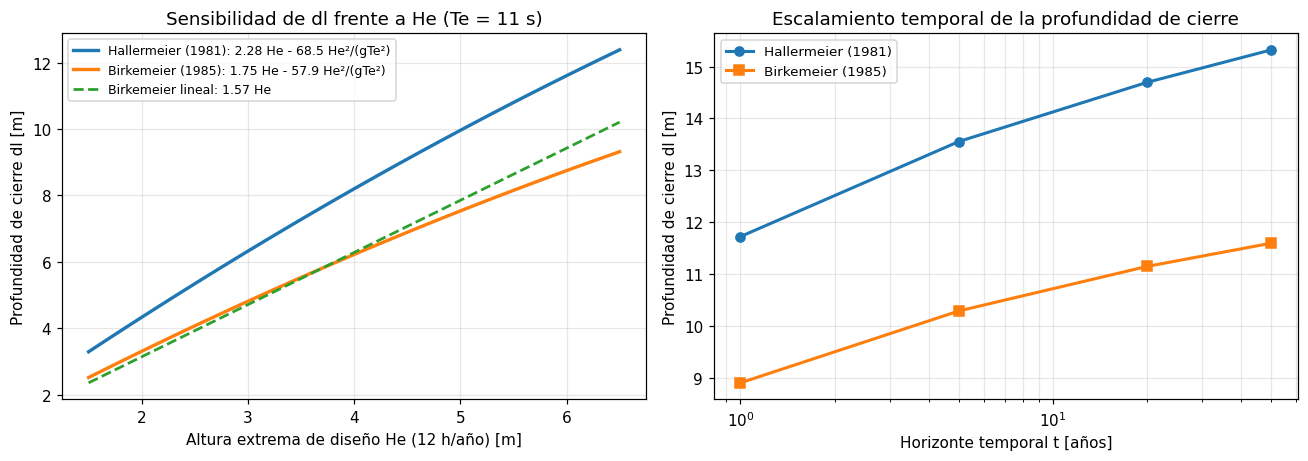

In [2]:
rng = np.random.default_rng(42)
# Serie sintética representativa de costa expuesta (~40 años trihorarios -> ~116 800 registros)
n_reg = 120_000
hs_ser = np.clip(rng.weibull(1.45, size=n_reg) * 1.45 + 0.30, 0.2, None)
tp_ser = np.clip(6.0 + 3.2 * np.sqrt(hs_ser) + rng.normal(0.0, 0.8, size=n_reg), 4.0, 20.0)

horizons = [1.0, 5.0, 20.0, 50.0]
res_h = [sm.closure.closure_depth_from_wave_series(hs_ser, tp_ser, years=yr, d50=0.00025) for yr in horizons]

for yr, r in zip(horizons, res_h):
    print(
        f"Horizonte {yr:4.0f} años -> He={r['He_m']:.2f} m (Te={r['Te_s']:.1f} s) | "
        f"Birkemeier dl={r['birkemeier_dl_m']:.2f} m | Hallermeier dl={r['hallermeier_dl_m']:.2f} m | "
        f"Outer di={r['hallermeier_di_outer_m']:.2f} m"
    )

he_grid = np.linspace(1.5, 6.5, 80)
cmp_g = sm.closure.compare_closure_depth_methods(he_grid, Te=11.0, H_mean=np.mean(hs_ser))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
ax1.plot(he_grid, cmp_g.hallermeier_dl_m, lw=2.2, label="Hallermeier (1981): 2.28 He - 68.5 He²/(gTe²)")
ax1.plot(he_grid, cmp_g.birkemeier_dl_m, lw=2.2, label="Birkemeier (1985): 1.75 He - 57.9 He²/(gTe²)")
ax1.plot(he_grid, cmp_g.birkemeier_linear_dl_m, "--", lw=1.8, label="Birkemeier lineal: 1.57 He")
ax1.set_xlabel("Altura extrema de diseño He (12 h/año) [m]")
ax1.set_ylabel("Profundidad de cierre dl [m]")
ax1.set_title("Sensibilidad de dl frente a He (Te = 11 s)")
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=8.2)

ax2.plot(horizons, [r["hallermeier_dl_m"] for r in res_h], "o-", lw=2.0, label="Hallermeier (1981)")
ax2.plot(horizons, [r["birkemeier_dl_m"] for r in res_h], "s-", lw=2.0, label="Birkemeier (1985)")
ax2.set_xscale("log")
ax2.set_xlabel("Horizonte temporal t [años]")
ax2.set_ylabel("Profundidad de cierre dl [m]")
ax2.set_title("Escalamiento temporal de la profundidad de cierre")
ax2.grid(True, which="both", alpha=0.3)
ax2.legend(fontsize=8.8)

plt.tight_layout()
plt.show()


## 2. Perfil de equilibrio de Dean y Regla de Bruun (+ extensión con *overwash*)

Para una profundidad de cierre anual de $d_c = 8.0\,\text{m}$ y altura de berma $B = 2.0\,\text{m}$, construimos los perfiles de equilibrio para tres granulometrías ($D_{50} = 0.18, 0.28, 0.50\,\text{mm}$) y evaluamos el retroceso esperado de la línea de costa ante un ascenso del nivel del mar de $0.1\text{ a }1.2\,\text{m}$.


Arena fina (0.18 mm): A=0.093 m^(1/3) | W*=795 m | Vol_eq=3818 m³/m | Bruun (SLR=0.5 m) -> R=39.8 m
Arena media (0.28 mm): A=0.122 m^(1/3) | W*=529 m | Vol_eq=2537 m³/m | Bruun (SLR=0.5 m) -> R=26.4 m
Arena gruesa (0.50 mm): A=0.158 m^(1/3) | W*=360 m | Vol_eq=1727 m³/m | Bruun (SLR=0.5 m) -> R=18.0 m


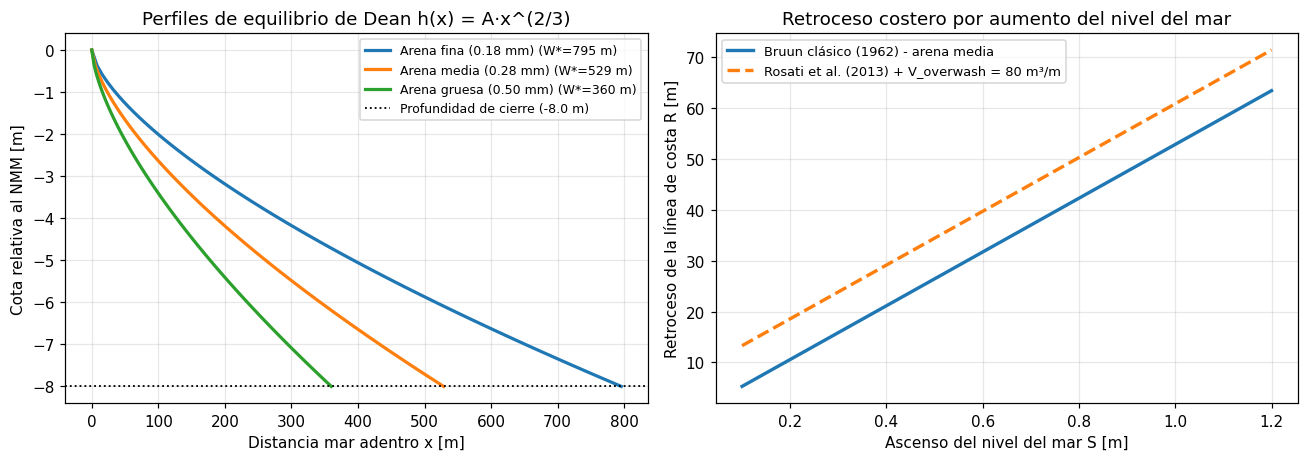

In [3]:
dc = 8.0
B = 2.0
d50_list = [0.00018, 0.00028, 0.00050]
labels = ["Arena fina (0.18 mm)", "Arena media (0.28 mm)", "Arena gruesa (0.50 mm)"]

slr_grid = np.linspace(0.1, 1.2, 50)
profiles = [sm.closure.equilibrium_profile_dean(dc, d50=d) for d in d50_list]

for lbl, p in zip(labels, profiles):
    br_05 = sm.closure.bruun_rule_recession(0.5, dc, berm_height=B, active_width=p.active_width_m)
    print(
        f"{lbl}: A={p.A_param:.3f} m^(1/3) | W*={p.active_width_m:.0f} m | "
        f"Vol_eq={p.profile_volume_m3_m:.0f} m³/m | Bruun (SLR=0.5 m) -> R={br_05.recession_m:.1f} m"
    )

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
for lbl, p in zip(labels, profiles):
    ax1.plot(p.x_m, -p.depth_m, lw=2.1, label=f"{lbl} (W*={p.active_width_m:.0f} m)")
ax1.axhline(-dc, color="k", ls=":", lw=1.2, label=f"Profundidad de cierre (-{dc:.1f} m)")
ax1.set_xlabel("Distancia mar adentro x [m]")
ax1.set_ylabel("Cota relativa al NMM [m]")
ax1.set_title("Perfiles de equilibrio de Dean h(x) = A·x^(2/3)")
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=8.2)

p_med = profiles[1]
br_pure = sm.closure.bruun_rule_recession(slr_grid, dc, berm_height=B, active_width=p_med.active_width_m)
br_ow = sm.closure.bruun_rule_recession(
    slr_grid, dc, berm_height=B, active_width=p_med.active_width_m, overwash_volume=80.0
)
ax2.plot(slr_grid, br_pure.recession_m, lw=2.2, label="Bruun clásico (1962) - arena media")
ax2.plot(slr_grid, br_ow.recession_m, "--", lw=2.2, label="Rosati et al. (2013) + V_overwash = 80 m³/m")
ax2.set_xlabel("Ascenso del nivel del mar S [m]")
ax2.set_ylabel("Retroceso de la línea de costa R [m]")
ax2.set_title("Retroceso costero por aumento del nivel del mar")
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()


## 3. Alimentación artificial de playas (*Beach Nourishment*) y obras transversales

Analizamos cómo cambia el volumen de arena requerido para ensanchar una playa nativa ($D_{50,N} = 0.25\,\text{mm}$) en $\Delta y_0 = 35\,\text{m}$ según se utilice arena nativa, préstamo más grueso ($0.40\,\text{mm}$, **perfil intersecante**) o préstamo más fino ($0.17\,\text{mm}$, **no intersecante**), y verificamos un espigón de $160\,\text{m}$ respecto a la zona activa.


Nativo (0.25 mm): V=350.0 m³/m | tipo=native_match
Grueso (0.40 mm): V=128.4 m³/m | tipo=intersecting | h_intersec=2.78 m | factor=0.37
Fino   (0.17 mm): V=1196.0 m³/m | tipo=non_intersecting | V_crit_sum=846.0 m³/m | factor=3.42
Espigón 160 m: h_tip=3.39 m | h_tip/dc=42.3% | L/W*=27.5%


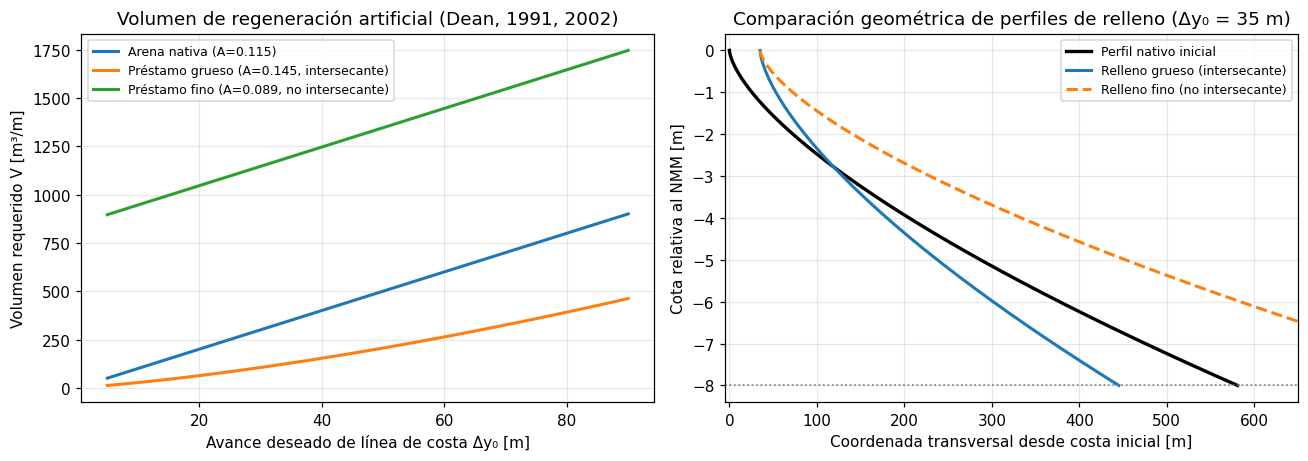

In [4]:
A_N = sm.closure.dean_scale_parameter(d50=0.00025)
A_coarse = sm.closure.dean_scale_parameter(d50=0.00040)
A_fine = sm.closure.dean_scale_parameter(d50=0.00017)

dy_target = 35.0
res_nat = sm.closure.beach_nourishment_volume(dy_target, dc, B, A_N, A_fill=A_N)
res_crs = sm.closure.beach_nourishment_volume(dy_target, dc, B, A_N, A_fill=A_coarse)
res_fin = sm.closure.beach_nourishment_volume(dy_target, dc, B, A_N, A_fill=A_fine)

groin = sm.closure.structure_active_depth_ratio(dc, structure_length=160.0, A_param=A_N)

print(f"Nativo (0.25 mm): V={res_nat.volume_m3_m:.1f} m³/m | tipo={res_nat.profile_type}")
print(f"Grueso (0.40 mm): V={res_crs.volume_m3_m:.1f} m³/m | tipo={res_crs.profile_type} | h_intersec={res_crs.intersection_depth_m:.2f} m | factor={res_crs.overfill_ratio_to_native:.2f}")
print(f"Fino   (0.17 mm): V={res_fin.volume_m3_m:.1f} m³/m | tipo={res_fin.profile_type} | V_crit_sum={res_fin.critical_submerged_volume_m3_m:.1f} m³/m | factor={res_fin.overfill_ratio_to_native:.2f}")
print(f"Espigón 160 m: h_tip={groin['depth_at_tip_m']:.2f} m | h_tip/dc={100*groin['active_depth_ratio']:.1f}% | L/W*={100*groin['active_width_ratio']:.1f}%")

dy_grid = np.linspace(5.0, 90.0, 60)
v_nat = [sm.closure.beach_nourishment_volume(float(dy), dc, B, A_N, A_fill=A_N).volume_m3_m for dy in dy_grid]
v_crs = [sm.closure.beach_nourishment_volume(float(dy), dc, B, A_N, A_fill=A_coarse).volume_m3_m for dy in dy_grid]
v_fin = [sm.closure.beach_nourishment_volume(float(dy), dc, B, A_N, A_fill=A_fine).volume_m3_m for dy in dy_grid]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
ax1.plot(dy_grid, v_nat, lw=2.0, label=f"Arena nativa (A={A_N:.3f})")
ax1.plot(dy_grid, v_crs, lw=2.0, label=f"Préstamo grueso (A={A_coarse:.3f}, intersecante)")
ax1.plot(dy_grid, v_fin, lw=2.0, label=f"Préstamo fino (A={A_fine:.3f}, no intersecante)")
ax1.set_xlabel("Avance deseado de línea de costa Δy₀ [m]")
ax1.set_ylabel("Volumen requerido V [m³/m]")
ax1.set_title("Volumen de regeneración artificial (Dean, 1991, 2002)")
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=8.2)

# Visualización geométrica de los tres perfiles equilibrados para Δy₀ = 35 m
h_plt = np.linspace(0.0, dc, 200)
x_native = (h_plt / A_N) ** 1.5
x_fill_c = dy_target + (h_plt / A_coarse) ** 1.5
x_fill_f = dy_target + (h_plt / A_fine) ** 1.5

ax2.plot(x_native, -h_plt, "k-", lw=2.2, label="Perfil nativo inicial")
ax2.plot(x_fill_c, -h_plt, lw=2.0, label="Relleno grueso (intersecante)")
ax2.plot(x_fill_f, -h_plt, "--", lw=2.0, label="Relleno fino (no intersecante)")
ax2.axhline(-dc, color="gray", ls=":", lw=1.1)
ax2.set_xlim(-5, 650)
ax2.set_xlabel("Coordenada transversal desde costa inicial [m]")
ax2.set_ylabel("Cota relativa al NMM [m]")
ax2.set_title("Comparación geométrica de perfiles de relleno (Δy₀ = 35 m)")
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=8.2)

plt.tight_layout()
plt.show()
